<a href="https://colab.research.google.com/github/HafizRizqi/MachineLearning_2026/blob/main/JS10/JS10_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#🌺Lab 1
Klasifikasi Bunga Iris dengan Perceptron

Pada praktikum ini, diminta untuk melakukan klasifikasi bunga iris dengan menggunakan model Perceptron. Anda dapat menggunakan dataset iris pada praktikum sebelumnya.

Untuk menambah pemahaman kita terkait dengan model Perceptron, pada praktikum ini kita akan membuat model Perceptron tanpa menggunakan library.

Langkah 1 - Import Library

In [1]:
	import numpy as np
	import matplotlib.pyplot as plt
	import pandas as pd
	import seaborn as sns

Langkah 2 - Load Data dan Visualisasi

In [9]:
from google.colab import files
uploaded = files.upload()

Saving iris.csv to iris (1).csv


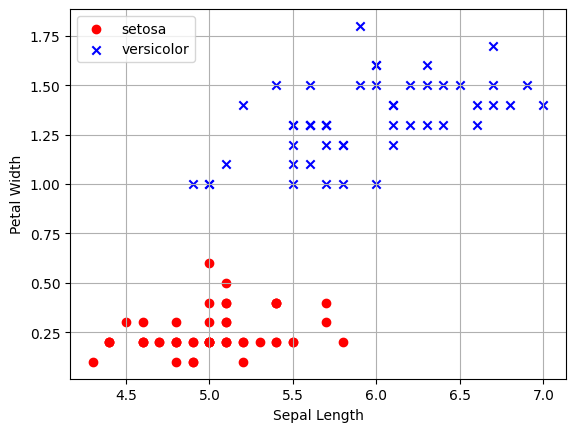

In [13]:
# Membaca dataset
df = pd.read_csv('iris.csv')

# Memisahkan data berdasarkan spesies
setosa = df[df['species'] == 'setosa']
versicolor = df[df['species'] == 'versicolor']

# Menentukan kolom
a, b = 0, 3

# Visualisasi
plt.scatter(setosa.iloc[:, a], setosa.iloc[:, b],
            color='red', marker='o', label='setosa')

plt.scatter(versicolor.iloc[:, a], versicolor.iloc[:, b],
            color='blue', marker='x', label='versicolor')

plt.xlabel('Sepal Length')
plt.ylabel('Petal Width')
plt.legend(loc='upper left')
plt.grid()
plt.show()

Langkah 3 - Membuat Kelas Perceptron

In [14]:
	class Perceptron(object):
	    def __init__(self, eta=0.01, n_iter=10):
	        self.eta = eta
	        self.n_iter = n_iter

	    def fit(self, X, y):

	        self.w_ = np.zeros(1 + X.shape[1])
	        self.errors_ = []

	        for _ in range(self.n_iter):
	            errors = 0
	            for xi, target in zip(X, y):
	                update = self.eta * (target - self.predict(xi))
	                self.w_[0] += update
	                self.w_[1:] += update * xi
	                errors += int(update != 0.0)
	            self.errors_.append(errors)
	        return self

	    def net_input(self, X):
	        return np.dot(X, self.w_[1:]) + self.w_[0]

	    def predict(self, X):
	        return np.where(self.net_input(X) >= 0.0, 1, -1)

Langkah 4 - Pilih Data dan Encoding Label

In [19]:
# Memilih 100 data pertama (50 setosa dan 50 versicolor)
y = df.iloc[0:100, 4].values

# Mengubah label kelas menjadi -1 dan 1 sesuai kebutuhan Perceptron
y = np.where(y == "setosa", -1, 1)

# Mengambil fitur kolom 0 dan 3: sepal length dan petal width
X = df.iloc[0:100, [0, 3]].values

# Memeriksa jumlah label setelah encoding
print("Jumlah kelas -1 (setosa):", np.sum(y == -1))
print("Jumlah kelas 1 (versicolor):", np.sum(y == 1))

Jumlah kelas -1 (setosa): 50
Jumlah kelas 1 (versicolor): 50


Langkah 5 - Fitting Model

In [20]:
	ppn = Perceptron(eta=0.1, n_iter=10)
ppn.fit(X, y)

print("Bobot akhir:", ppn.w_)
print("Jumlah update per epoch:", ppn.errors_)

Bobot akhir: [-0.4  -0.1   1.12]
Jumlah update per epoch: [2, 2, 2, 3, 2, 1, 0, 0, 0, 0]


Langkah 6 - Visualisasi Nilai Error Per Epoch

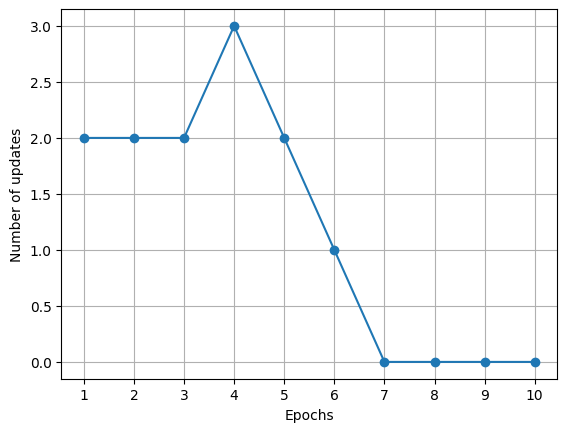

In [21]:
	plt.plot(range(1, len(ppn.errors_) + 1), ppn.errors_, marker="o")
plt.xlabel("Epochs")
plt.ylabel("Number of updates")
plt.xticks(range(1, len(ppn.errors_) + 1))
plt.grid()
plt.show()

Langkah 7 - Visualisasi Decision Boundary

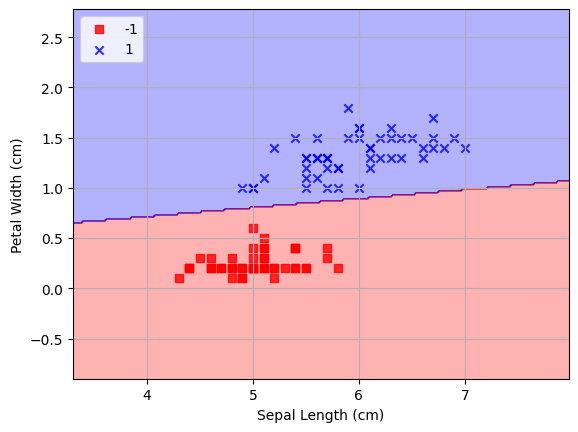

In [22]:
	from matplotlib.colors import ListedColormap

def plot_decision_regions(X, y, classifier, resolution=0.02):
    # Marker dan warna untuk setiap kelas
    markers = ("s", "x", "o", "^", "v")
    colors = ("red", "blue", "green", "black", "grey")
    cmap = ListedColormap(colors[:len(np.unique(y))])

    # Membuat grid untuk menggambar daerah keputusan
    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx1, xx2 = np.meshgrid(
        np.arange(x1_min, x1_max, resolution),
        np.arange(x2_min, x2_max, resolution)
    )

    # Memprediksi kelas pada setiap titik grid
    Z = classifier.predict(np.array([xx1.ravel(), xx2.ravel()]).T)
    Z = Z.reshape(xx1.shape)

    # Menggambar decision regions
    plt.contourf(xx1, xx2, Z, alpha=0.3, cmap=cmap)
    plt.xlim(xx1.min(), xx1.max())
    plt.ylim(xx2.min(), xx2.max())

    # Menggambar titik data asli
    for i, cl in enumerate(np.unique(y)):
        plt.scatter(
            X[y == cl, 0], X[y == cl, 1],
            alpha=0.8, c=[cmap(i)], marker=markers[i], label=cl
        )

# Memanggil fungsi agar Decision Boundary benar-benar ditampilkan
plot_decision_regions(X, y, classifier=ppn)
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.legend(loc="upper left")
plt.grid()
plt.show()